<a href="https://colab.research.google.com/github/pradhandeban5/ViT-model-for-detecting-deepfake-images/blob/main/Another_copy_of_VIT1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#library
import torch
import torchvision
import torchvision.transforms as transforms
import torch.utils.data as dataloader
import torch.nn as nn
import kagglehub

In [ ]:
#variables
num_classes=2
batch_size=70
num_channels=3 # Deepfake images are typically RGB, so 3 channels
img_size=256 # Increase image size for better feature extraction in deepfake detection
patch_size=16 # Adjust patch size accordingly for new img_size
num_patches=(img_size // patch_size) ** 2
embedding_dim=768
attention_heads=12
transformer_blocks=4
mlp_hidden_nodes=128
learning_rate=0.0001 # Reduced learning rate
epochs=20

In [ ]:
#Conversion to tensor
train_transformation_operation = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomHorizontalFlip(), # Add random horizontal flip
    transforms.RandomRotation(10),     # Add random rotation
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1), # Add color jitter
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transformation_operation = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [ ]:
#dataset
import os
from torch.utils.data import random_split

# Download the dataset
path = kagglehub.dataset_download("sachchitkunichetty/rvf10k")

# Corrected: Based on the provided folder structure, 'train' and 'valid' are directly under 'rvf10k'
dataset_root = os.path.join(path, 'rvf10k')

# Define the target transform to remap labels:
# ImageFolder assigns labels alphabetically: {'fake': 0, 'real': 1}
# We want: 'real' -> 0, 'fake' -> 1
# So, if original label is 0 (fake), remap to 1. If original label is 1 (real), remap to 0.
target_transform_remapper = lambda label: 1 - label

train_dataset = torchvision.datasets.ImageFolder(
    root=os.path.join(dataset_root, 'train'),
    transform=train_transformation_operation, # Use train_transformation_operation
    target_transform=target_transform_remapper
)
val_dataset = torchvision.datasets.ImageFolder(
    root=os.path.join(dataset_root, 'valid'),
    transform=val_transformation_operation, # Use val_transformation_operation
    target_transform=target_transform_remapper
)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")

Using Colab cache for faster access to the 'rvf10k' dataset.
Training dataset size: 7000
Validation dataset size: 3000


Let's inspect the contents of the `train` directory to see the class folders.

### Verifying Label Mapping

To confirm that 'real' images are mapped to label `0` and 'fake' images to label `1` for training, we can inspect the `class_to_idx` from the dataset (which shows the initial mapping) and then sample a batch from the `train_loader` to see the actual labels after the `target_transform` is applied.

In [ ]:
import torch

# Verification of Label Mapping
try:
    print(f"Original ImageFolder class mapping: {train_dataset.class_to_idx}")
    # Get a batch from the train_loader to see the actual labels being used
    first_batch_images, first_batch_labels = next(iter(train_loader))
    print(f"\nSample of actual labels from the training loader (after target_transform): {first_batch_labels[:10].tolist()}")
    print("Expected: 0 for real, 1 for fake.")
except NameError as e:
    print(f"Error: {e}. Please ensure you have run the '#dataset batches' cell (PadnPM9rCDaH) first.")

Original ImageFolder class mapping: {'fake': 0, 'real': 1}

Sample of actual labels from the training loader (after target_transform): [0, 1, 0, 1, 0, 1, 0, 1, 0, 1]
Expected: 0 for real, 1 for fake.


In [ ]:
#dataset batches
train_loader=dataloader.DataLoader(dataset=train_dataset,batch_size=batch_size,shuffle=True)
val_loader=dataloader.DataLoader(dataset=val_dataset,batch_size=batch_size,shuffle=True)

# Verify labels
print(f"Original ImageFolder class mapping: {train_dataset.class_to_idx}")
first_batch_images, first_batch_labels = next(iter(train_loader))
print(f"Sample labels (0=real, 1=fake): {first_batch_labels[:10].tolist()}")

Original ImageFolder class mapping: {'fake': 0, 'real': 1}
Sample labels (0=real, 1=fake): [0, 0, 1, 0, 1, 1, 1, 1, 0, 0]


### Verifying Label Mapping

To confirm that 'real' images are mapped to label `0` and 'fake' images to label `1` for training, we can inspect the `class_to_idx` from the dataset and sample a batch from the `train_loader`.

In [ ]:
#patch embedding
class PatchEmbedding(nn.Module):
  def __init__(self):
    super().__init__()
    self.patch_embed=nn.Conv2d(num_channels, embedding_dim, kernel_size=patch_size, stride=patch_size)

  def forward(self, x):
    #embedding
    x=self.patch_embed(x)
    #flattening
    x=x.flatten(2)
    x=x.transpose(1,2)
    return x
    #classtoken

In [ ]:
#transformer encoder
class TransformerEncoder(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer_norm1=nn.LayerNorm(embedding_dim)
    self.layer_norm2=nn.LayerNorm(embedding_dim)
    self.multihead_attention=nn.MultiheadAttention(embedding_dim,attention_heads,batch_first=True)
    self.mlp=nn.Sequential(
        nn.Linear(embedding_dim,mlp_hidden_nodes),
        nn.GELU(),
        nn.Linear(mlp_hidden_nodes,embedding_dim),
    )

  def forward(self,x):
    residual1=x
    x=self.layer_norm1(x)
    x=self.multihead_attention(x,x,x)[0]
    x=x+residual1
    residual2=x
    x=self.layer_norm2(x)
    x=self.mlp(x)
    x=x+residual2
    return x

In [ ]:
#mlphead
class MLPHead(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer_norm1=nn.LayerNorm(embedding_dim)
    self.mlp_head=nn.Linear(embedding_dim,num_classes)

  def forward(self,x):
    x=self.layer_norm1(x)
    #x=x[:,0]
    x=self.mlp_head(x)
    return x


In [ ]:
#class
class VisionTransformer(nn.Module):
  def __init__(self):
    super().__init__()
    self.patch_embedding=PatchEmbedding()
    #clstoken
    self.cls_token=nn.Parameter(torch.randn(1,1,embedding_dim))
    #positionembedding
    self.position_embedding=nn.Parameter(torch.randn(1,num_patches+1,embedding_dim))
    #transformer encoder
    self.transformer_blocks=nn.Sequential(*[TransformerEncoder() for _ in range(transformer_blocks)])
    #mlphead
    self.mlp_head=MLPHead()

  def forward(self,x):
    x=self.patch_embedding(x)
    class_token=self.cls_token.expand(x.size(0),-1,-1)
    x=torch.cat((class_token,x),dim=1)
    x=x+self.position_embedding
    x=self.transformer_blocks(x)
    x=x[:,0]
    x=self.mlp_head(x)
    return x

In [ ]:
#
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model=VisionTransformer().to(device)
optimizer=torch.optim.Adam(model.parameters(),lr=learning_rate)
criterion=nn.CrossEntropyLoss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

In [ ]:
# freeze check
print("Checking if model parameters are frozen:")
for name, param in model.named_parameters():
    print(f"Parameter: {name}, Requires Grad: {param.requires_grad}")

if all(not param.requires_grad for param in model.parameters()):
    print("\nAll parameters are frozen. The model is frozen.")
else:
    print("\nSome parameters are trainable. The model is not entirely frozen.")

Checking if model parameters are frozen:
Parameter: cls_token, Requires Grad: True
Parameter: position_embedding, Requires Grad: True
Parameter: patch_embedding.patch_embed.weight, Requires Grad: True
Parameter: patch_embedding.patch_embed.bias, Requires Grad: True
Parameter: transformer_blocks.0.layer_norm1.weight, Requires Grad: True
Parameter: transformer_blocks.0.layer_norm1.bias, Requires Grad: True
Parameter: transformer_blocks.0.layer_norm2.weight, Requires Grad: True
Parameter: transformer_blocks.0.layer_norm2.bias, Requires Grad: True
Parameter: transformer_blocks.0.multihead_attention.in_proj_weight, Requires Grad: True
Parameter: transformer_blocks.0.multihead_attention.in_proj_bias, Requires Grad: True
Parameter: transformer_blocks.0.multihead_attention.out_proj.weight, Requires Grad: True
Parameter: transformer_blocks.0.multihead_attention.out_proj.bias, Requires Grad: True
Parameter: transformer_blocks.0.mlp.0.weight, Requires Grad: True
Parameter: transformer_blocks.0.ml

In [ ]:
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for epoch in range(epochs):
  model.train()
  total_loss=0
  correct_epoch=0
  total_epoch=0

  train_pred_real_count = 0
  train_pred_fake_count = 0

  print(f"\nEpoch {epoch+1}")

  for batch_idx,(images,labels) in enumerate(train_loader):
    images=images.to(device)
    labels=labels.to(device)
    optimizer.zero_grad()
    outputs=model(images)
    loss=criterion(outputs,labels)
    loss.backward()
    optimizer.step()
    total_loss+=loss.item()
    preds=outputs.argmax(dim=1)

    # Accumulate counts for predicted classes in training
    train_pred_real_count += (preds == 0).sum().item()
    train_pred_fake_count += (preds == 1).sum().item()

    correct=(preds==labels).sum().item()
    accuracy=100.0*correct/labels.size(0)
    correct_epoch+=correct
    total_epoch+=labels.size(0)
    if batch_idx %100==0:
      print(f"Batch {batch_idx+1}/{len(train_loader)}, Train Loss: {loss.item():.4f}, Train Accuracy: {accuracy:.2f}%")

  epoch_acc=100.0 * correct_epoch / total_epoch
  train_losses.append(total_loss/len(train_loader))
  train_accuracies.append(epoch_acc)
  train_pred_real_percentage = (train_pred_real_count / total_epoch) * 100
  train_pred_fake_percentage = (train_pred_fake_count / total_epoch) * 100

  print(f"==> Epoch {epoch+1} Summary: Average Train Loss: {total_loss/len(train_loader):.4f}, Train Accuracy: {epoch_acc:.2f}%")
  print(f"    Train Predicted: Real: {train_pred_real_percentage:.2f}%, Fake: {train_pred_fake_percentage:.2f}%")

  # Validation loop
  model.eval()
  val_total_loss = 0
  val_correct_epoch = 0
  val_total_epoch = 0

  val_pred_real_count = 0
  val_pred_fake_count = 0

  with torch.no_grad():
    for images, labels in val_loader:
      images = images.to(device)
      labels = labels.to(device)
      outputs = model(images)
      loss = criterion(outputs, labels)
      val_total_loss += loss.item()
      preds = outputs.argmax(dim=1)

      # Accumulate counts for predicted classes in validation
      val_pred_real_count += (preds == 0).sum().item()
      val_pred_fake_count += (preds == 1).sum().item()

      val_correct_epoch += (preds == labels).sum().item()
      val_total_epoch += labels.size(0)

  val_epoch_acc = 100.0 * val_correct_epoch / val_total_epoch
  val_losses.append(val_total_loss/len(val_loader))
  val_accuracies.append(val_epoch_acc)
  val_pred_real_percentage = (val_pred_real_count / val_total_epoch) * 100
  val_pred_fake_percentage = (val_pred_fake_count / val_total_epoch) * 100

  print(f"==> Epoch {epoch+1} Validation Summary: Average Val Loss: {val_total_loss/len(val_loader):.4f}, Val Accuracy: {val_epoch_acc:.2f}%")
  print(f"    Validation Predicted: Real: {val_pred_real_percentage:.2f}%, Fake: {val_pred_fake_percentage:.2f}%")

  # Step the learning rate scheduler
  scheduler.step(val_total_loss/len(val_loader))


Epoch 1
Batch 1/100, Train Loss: 0.6897, Train Accuracy: 54.29%
==> Epoch 1 Summary: Average Train Loss: 0.6883, Train Accuracy: 55.89%
    Train Predicted: Real: 47.69%, Fake: 52.31%
==> Epoch 1 Validation Summary: Average Val Loss: 0.6176, Val Accuracy: 66.70%
    Validation Predicted: Real: 61.10%, Fake: 38.90%

Epoch 2
Batch 1/100, Train Loss: 0.5939, Train Accuracy: 72.86%
==> Epoch 2 Summary: Average Train Loss: 0.6172, Train Accuracy: 66.10%
    Train Predicted: Real: 48.93%, Fake: 51.07%
==> Epoch 2 Validation Summary: Average Val Loss: 0.5870, Val Accuracy: 68.47%
    Validation Predicted: Real: 35.67%, Fake: 64.33%

Epoch 3
Batch 1/100, Train Loss: 0.6811, Train Accuracy: 60.00%
==> Epoch 3 Summary: Average Train Loss: 0.5864, Train Accuracy: 68.69%
    Train Predicted: Real: 50.20%, Fake: 49.80%
==> Epoch 3 Validation Summary: Average Val Loss: 0.5825, Val Accuracy: 68.83%
    Validation Predicted: Real: 33.70%, Fake: 66.30%

Epoch 4
Batch 1/100, Train Loss: 0.4576, Train A

### Training Evolution Plots

Let's visualize the training and validation loss and accuracy over epochs to understand the model's learning progress and identify potential overfitting or underfitting.

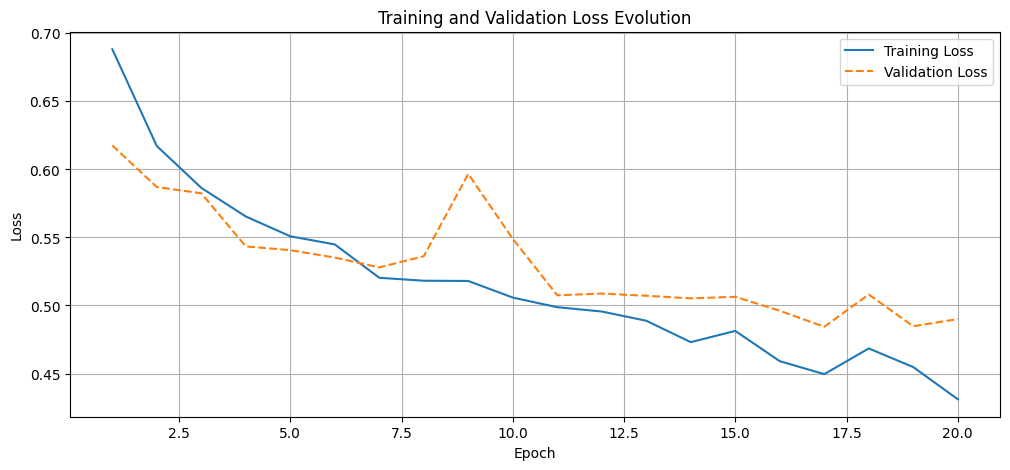

In [ ]:
import matplotlib.pyplot as plt

# Plot Training and Validation Loss
plt.figure(figsize=(12, 5))
plt.plot(range(1, epochs + 1), train_losses, label='Training Loss')
plt.plot(range(1, epochs + 1), val_losses, label='Validation Loss', linestyle='--')
plt.title('Training and Validation Loss Evolution')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

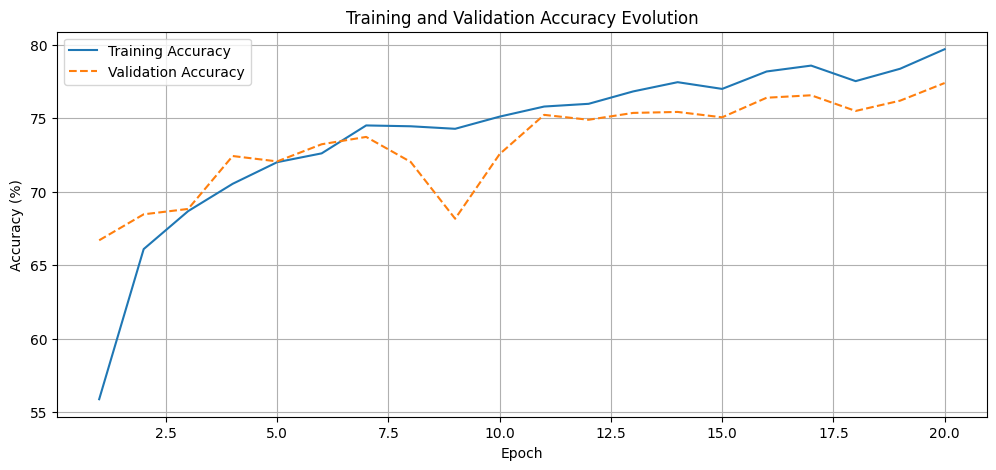

In [ ]:
import matplotlib.pyplot as plt

# Plot Training and Validation Accuracy
plt.figure(figsize=(12, 5))
plt.plot(range(1, epochs + 1), train_accuracies, label='Training Accuracy')
plt.plot(range(1, epochs + 1), val_accuracies, label='Validation Accuracy', linestyle='--')
plt.title('Training and Validation Accuracy Evolution')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.show()

### Classification Report for Validation Set

Here is a detailed classification report for the model's performance on the validation set, including precision, recall, f1-score, and support for each class ('real' and 'fake').

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

model.eval()
all_labels = []
all_preds = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# Define target names according to the remapping (0 for real, 1 for fake)
target_names = ['real', 'fake']

print(classification_report(all_labels, all_preds, target_names=target_names))

# Optionally, visualize the confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Validation Set')
plt.show()

NameError: name 'model' is not defined

### Predict on New Images

This section provides functionality to upload new images (either individual JPG/PNG files or a ZIP archive containing multiple images) and use the trained model to predict whether they are 'real' or 'deepfake'.

In [ ]:
import zipfile
import io
from PIL import Image
from google.colab import files
import torch
import torch.nn.functional as F

def preprocess_single_image(image_path_or_buffer):
    """Preprocesses a single image for model inference."""
    if isinstance(image_path_or_buffer, str):
        image = Image.open(image_path_or_buffer).convert("RGB")
    else: # Assume it's a BytesIO object
        image = Image.open(image_path_or_buffer).convert("RGB")
    return val_transformation_operation(image).unsqueeze(0).to(device) # Use val_transformation_operation for inference

def predict_on_uploaded_images():
    """Uploads images, preprocesses them, and makes predictions, returning probabilities."""
    uploaded = files.upload()

    model.eval() # Set model to evaluation mode
    # Define class names according to the remapping: 0 for real, 1 for fake
    class_names = ['real', 'fake']

    all_image_data = [] # To store (img_buffer, original_filename)
    for filename, content in uploaded.items():
        if filename.endswith('.zip'):
            # Extract images from zip file
            with zipfile.ZipFile(io.BytesIO(content), 'r') as zf:
                for member in zf.namelist():
                    if member.endswith(('.jpg', '.jpeg', '.png')) and not member.startswith('__MACOSX'):
                        with zf.open(member) as file:
                            all_image_data.append((io.BytesIO(file.read()), member)) # Store content and original name
        elif filename.endswith(('.jpg', '.jpeg', '.png')):
            all_image_data.append((io.BytesIO(content), filename)) # Store content and original name
        else:
            print(f"Skipping unsupported file: {filename}")

    if not all_image_data:
        print("No valid image files found for prediction.")
        return [] # Return empty list if no images

    print("\n--- Predictions ---")
    results = []
    with torch.no_grad():
        for img_buffer, original_filename in all_image_data:
            try:
                input_tensor = preprocess_single_image(img_buffer)
                outputs = model(input_tensor)
                probabilities = F.softmax(outputs, dim=1)[0] # Get probabilities for the single image
                _, predicted_idx = torch.max(probabilities, 0) # Get index of max probability
                predicted_class = class_names[predicted_idx.item()]
                prediction_percentage = probabilities[predicted_idx.item()].item() * 100

                real_prob = probabilities[0].item() * 100 # Probability for 'real' (label 0)
                fake_prob = probabilities[1].item() * 100 # Probability for 'fake' (label 1)

                print(f"Image: {original_filename} -> Predicted: {predicted_class} ({prediction_percentage:.2f}%) "
                      f"[Real: {real_prob:.2f}%, Fake: {fake_prob:.2f}%]")

                results.append({
                    "filename": original_filename,
                    "predicted_class": predicted_class,
                    "prediction_confidence": prediction_percentage,
                    "probabilities": {"real": real_prob, "fake": fake_prob}
                })
            except Exception as e:
                print(f"Error processing {original_filename}: {e}")
                results.append({"filename": original_filename, "error": str(e)})

    return results

# Call the function to start the upload and prediction process and store the results
predictions_result = predict_on_uploaded_images()

# Optionally, print a summary of the returned results
if predictions_result:
  print("\n--- Returned Predictions Summary ---")
  for res in predictions_result:
    if "error" in res:
      print(f"  {res['filename']}: Error - {res['error']}")
    else:
      print(f"  {res['filename']}: Predicted {res['predicted_class']} ({res['prediction_confidence']:.2f}%) "
            f"(Real: {res['probabilities']['real']:.2f}%, Fake: {res['probabilities']['fake']:.2f}%)")

Streaming output truncated to the last 5000 lines.
  rvf10k/train/real/28016.jpg: Predicted real (91.78%) (Real: 91.78%, Fake: 8.22%)
  rvf10k/train/real/28024.jpg: Predicted real (85.58%) (Real: 85.58%, Fake: 14.42%)
  rvf10k/train/real/28056.jpg: Predicted real (88.16%) (Real: 88.16%, Fake: 11.84%)
  rvf10k/train/real/28081.jpg: Predicted real (80.77%) (Real: 80.77%, Fake: 19.23%)
  rvf10k/train/real/28160.jpg: Predicted real (93.90%) (Real: 93.90%, Fake: 6.10%)
  rvf10k/train/real/28181.jpg: Predicted real (65.47%) (Real: 65.47%, Fake: 34.53%)
  rvf10k/train/real/28190.jpg: Predicted real (90.36%) (Real: 90.36%, Fake: 9.64%)
  rvf10k/train/real/28192.jpg: Predicted real (87.39%) (Real: 87.39%, Fake: 12.61%)
  rvf10k/train/real/28194.jpg: Predicted real (87.53%) (Real: 87.53%, Fake: 12.47%)
  rvf10k/train/real/28197.jpg: Predicted real (81.29%) (Real: 81.29%, Fake: 18.71%)
  rvf10k/train/real/28199.jpg: Predicted real (95.10%) (Real: 95.10%, Fake: 4.90%)
  rvf10k/train/real/28247.jpg

### Testing Results with New Images

The `predict_on_uploaded_images()` function above allows you to upload new images and get predictions. Below, I will display these predictions in a tabular format. Please note that metrics like F1-score, accuracy, and support require **ground truth labels**, which are not available for arbitrary user-uploaded images. Therefore, these metrics cannot be calculated for the "new images" in this section.

In [ ]:
import pandas as pd

if predictions_result:
    # Convert the list of dictionaries to a pandas DataFrame for tabular display
    df_predictions = pd.DataFrame(predictions_result)

    # Flatten the probabilities dictionary into separate columns
    if 'probabilities' in df_predictions.columns:
        df_predictions[['Real Probability', 'Fake Probability']] = df_predictions['probabilities'].apply(lambda x: pd.Series([x['real'], x['fake']]))
        df_predictions = df_predictions.drop(columns=['probabilities'])

    print("\n--- Predictions for Uploaded Images ---")
    display(df_predictions.set_index('filename'))
else:
    print("No new images were uploaded or processed.")


--- Predictions for Uploaded Images ---


,predicted_class,prediction_confidence,Real Probability,Fake Probability
filename,,,,
rvf10k/train/fake/002KDWZBHU.jpg,fake,62.645650,37.354347,62.645650
rvf10k/train/fake/009X14ED19.jpg,fake,94.183320,5.816678,94.183320
rvf10k/train/fake/00GYML2PNL.jpg,fake,93.406552,6.593446,93.406552
rvf10k/train/fake/017VGJOA5T.jpg,fake,54.033822,45.966175,54.033822
rvf10k/train/fake/019MPFQ50W.jpg,fake,65.469658,34.530336,65.469658
...,...,...,...,...
rvf10k/valid/real/69471.jpg,fake,71.752089,28.247911,71.752089
rvf10k/valid/real/69484.jpg,real,98.029035,98.029035,1.970964
rvf10k/valid/real/69562.jpg,fake,89.870465,10.129537,89.870465
